### Загрузка и предобработка данных

In [6]:
!unzip -o data.zip -d data

Archive:  data.zip
  inflating: data/reddit_ru.csv      
  inflating: data/tokenizer.pickle   
  inflating: data/model.keras        


In [7]:
import pandas as pd


df = pd.read_csv('data/reddit_ru.csv')
df = df.drop_duplicates()
df.head()

,comment
0,"I'm a bot, *bleep*, *bloop*. Someone has linke..."
1,[removed]
2,"Ваш пост был автоматически удален, потому что ..."
3,дурачок
4,Импорт закрыли => доллары тратить некуда => до...


In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 5753 entries, 0 to 5989
Data columns (total 1 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   comment  5753 non-null   object
dtypes: object(1)
memory usage: 89.9+ KB


In [9]:
import re


def clean_text(text):
    text = text.lower()
    text = re.sub(r'http\S+', '', text)
    text = re.sub(r'www\S+', '', text)
    text = re.sub(r"\'s", " ", text)
    text = re.sub('\W', ' ', text)
    text = re.sub('\s+', ' ', text)
    text = text.strip(' ')
    return text

df['comment'] = df['comment'].apply(clean_text)
print(df.shape)
df.head()

(5753, 1)


,comment
0,i m a bot bleep bloop someone has linked to th...
1,removed
2,ваш пост был автоматически удален потому что в...
3,дурачок
4,импорт закрыли доллары тратить некуда доллары ...


In [10]:
# пропусков нет
df.isnull().sum()

,0
comment,0


In [11]:
# уберем сообщения с долей латинницы >= 0.4
is_en = lambda x: len(re.findall('[a-z]', x)) / max(len(x.replace(' ', '')), 1)
df = df[df['comment'].apply(is_en) < 0.4]
print(df.shape)

(5470, 1)


In [12]:
df.apply(lambda x: len(x['comment']), axis=1).describe()

,0
count,5470.000000
mean,95.715722
std,220.371918
min,0.000000
25%,21.000000
50%,46.000000
75%,97.000000
max,7866.000000


In [13]:
# уберем пустые комментарии и слишком длинные
df = df[df['comment'] != '']
df = df[(df['comment'].apply(lambda x: len(x)) < 300)]
df.shape

(5097, 1)

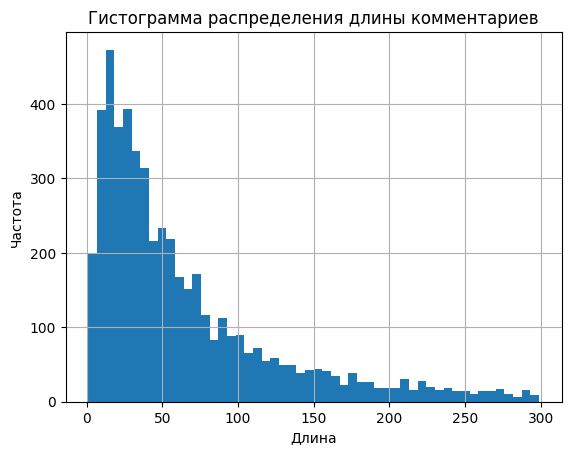

In [14]:
import matplotlib.pyplot as plt


df.apply(lambda x: len(x['comment']), axis=1).hist(bins=52)
plt.xlabel('Длина')
plt.ylabel('Частота')
plt.title('Гистограмма распределения длины комментариев')
plt.show()

### Частотный анализ слов, n-граммы

In [15]:
import nltk
nltk.download('punkt')
nltk.download('stopwords')
from nltk import word_tokenize
from nltk.probability import FreqDist
from nltk.corpus import stopwords
from nltk.util import ngrams

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


[('и', 1616), ('не', 1603), ('в', 1332), ('на', 850), ('что', 850), ('а', 763), ('это', 730), ('я', 718), ('с', 614), ('то', 600)]


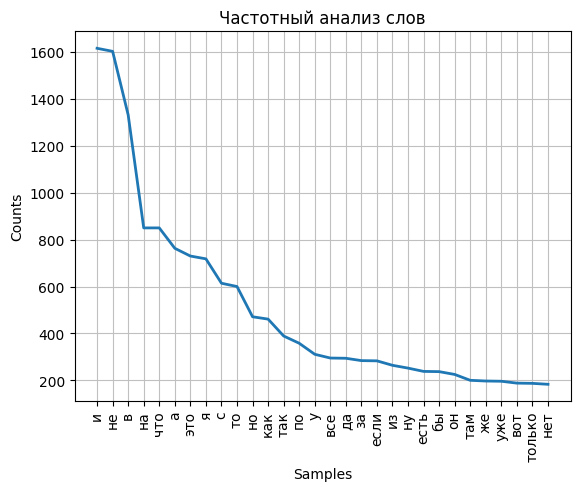

<Axes: title={'center': 'Частотный анализ слов'}, xlabel='Samples', ylabel='Counts'>

In [16]:
# Частотный анализ слов
comments = " ".join(df['comment'].tolist())
comments_tokens = word_tokenize(comments)
text = nltk.Text(comments_tokens)
f_dist = FreqDist(text)
print(f_dist.most_common(10))
f_dist.plot(30, cumulative=False, title='Частотный анализ слов')

('просто', 157)
('аниме', 145)
('ещё', 142)
('всё', 129)
('спасибо', 119)
('очень', 107)
('вообще', 88)
('3', 80)
('2', 78)
('пока', 77)


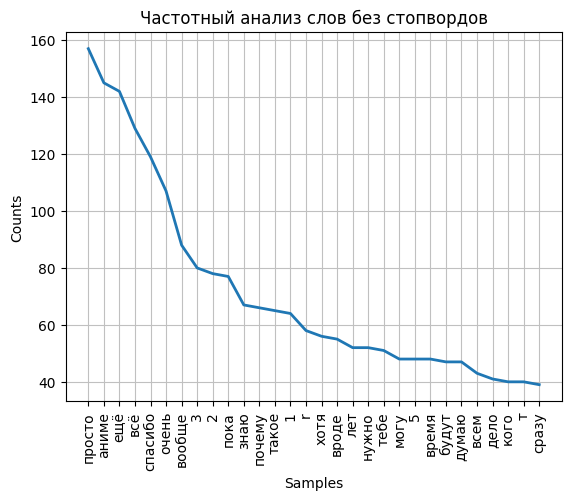

<Axes: title={'center': 'Частотный анализ слов без стопвордов'}, xlabel='Samples', ylabel='Counts'>

In [17]:
ru_stopwords = stopwords.words("russian") + ['это', 'её']
text_f = [word for word in text if word not in ru_stopwords]
f_dist = FreqDist(text_f)
print('\n'.join(map(str, f_dist.most_common(10))))
f_dist.plot(30, cumulative=False, title='Частотный анализ слов без стопвордов')

(('сих', 'пор'), 15)
(('люблю', 'макароны'), 13)
(('т', 'д'), 13)
(('всё', 'равно'), 12)
(('самом', 'деле'), 11)
(('всем', 'привет'), 10)
(('крайней', 'мере'), 9)
(('макароны', 'люблю'), 9)
(('ха', 'ха'), 8)
(('т', 'е'), 8)


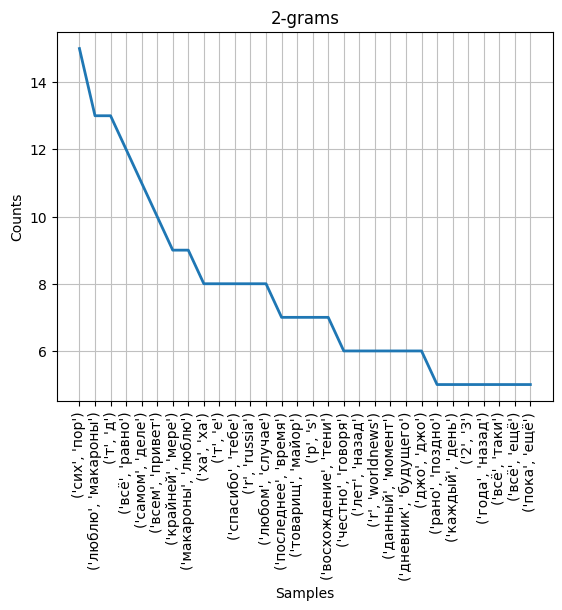

<Axes: title={'center': '2-grams'}, xlabel='Samples', ylabel='Counts'>

In [18]:
from functools import reduce


df['tokenized'] = df['comment'].apply(lambda x: word_tokenize(x)).apply(lambda x: [word  for word in x if word not in ru_stopwords])
df['2-grams'] = df['tokenized'].apply(lambda x: list(ngrams(x, 2)))
bigrams = reduce(lambda x, y: x + y, df['2-grams'].values)
f_dist = FreqDist(bigrams)
print('\n'.join(map(str, f_dist.most_common(10))))
f_dist.plot(30, cumulative=False, title='2-grams')

(('люблю', 'макароны', 'люблю'), 9)
(('макароны', 'люблю', 'макароны'), 9)
(('эта', 'фарфоровая', 'кукла'), 4)
(('половые', 'органы', 'дедушки'), 3)
(('текст', 'красненьким', 'irony'), 3)
(('тех', 'пор', 'пока'), 3)
(('фарфоровая', 'кукла', 'влюбилась'), 3)
(('последний', 'путь', 'фрирен'), 3)
(('800', 'летняя', 'жена'), 3)
(('всё', 'ловлю', 'лету'), 3)


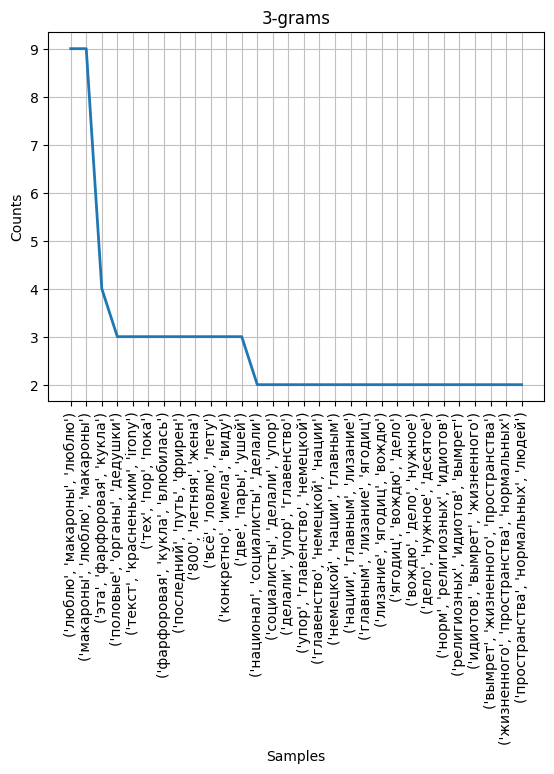

<Axes: title={'center': '3-grams'}, xlabel='Samples', ylabel='Counts'>

In [19]:
df['3-grams'] = df['tokenized'].apply(lambda x: list(ngrams(x, 3)))
threegrams = reduce(lambda x, y: x + y, df['3-grams'].values)
f_dist = FreqDist(threegrams)
print('\n'.join(map(str, f_dist.most_common(10))))
f_dist.plot(30, cumulative=False, title='3-grams')

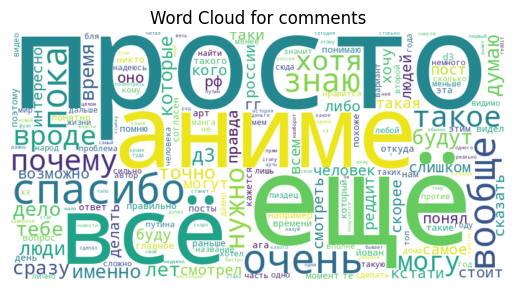

In [20]:
from wordcloud import WordCloud


wordcloud_toxic = WordCloud(width=800, height=400, background_color='white').generate(' '.join(text_f))
plt.imshow(wordcloud_toxic, interpolation='bilinear')
plt.axis('off')
plt.title('Word Cloud for comments')
plt.show()

### Стемминг и лемматизация

In [21]:
!pip install pymorphy2
import pymorphy2

  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 55.5/55.5 kB 2.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.2/8.2 MB 49.1 MB/s eta 0:00:00
  Created wheel for docopt: filename=docopt-0.6.2-py2.py3-none-any.whl size=13706 sha256=6e115c3d28661123f400b0179472c5da88afe8a215f6b9c5ffda43c7502221ce
  Stored in directory: /root/.cache/pip/wheels/fc/ab/d4/5da2067ac95b36618c629a5f93f809425700506f72c9732fac
Successfully built docopt


('такой', 230)
('год', 169)
('просто', 157)
('аниме', 145)
('человек', 142)
('ещё', 142)
('быть', 136)
('знать', 133)
('всё', 129)
('который', 128)


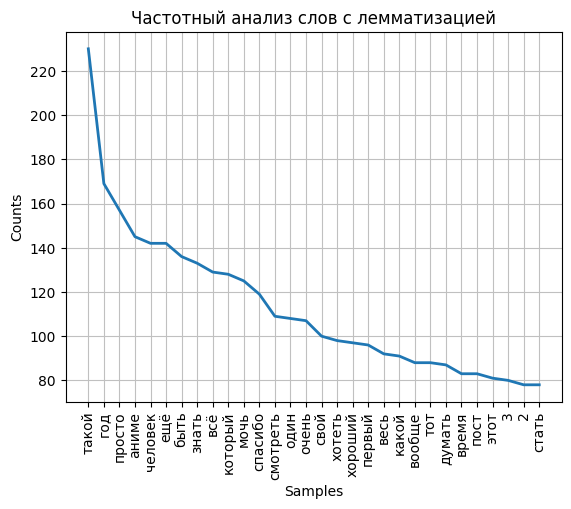

<Axes: title={'center': 'Частотный анализ слов с лемматизацией'}, xlabel='Samples', ylabel='Counts'>

In [22]:
# Лемматизация
morph = pymorphy2.MorphAnalyzer()

text_lemmatized = map(lambda word: morph.parse(word)[0].normal_form, text_f)
f_dist = FreqDist(text_lemmatized)
print('\n'.join(map(str, f_dist.most_common(10))))
f_dist.plot(30, cumulative=False, title='Частотный анализ слов с лемматизацией')

('так', 265)
('прост', 182)
('аним', 147)
('ещ', 143)
('все', 138)
('сам', 137)
('котор', 128)
('спасиб', 121)
('одн', 108)
('эт', 107)


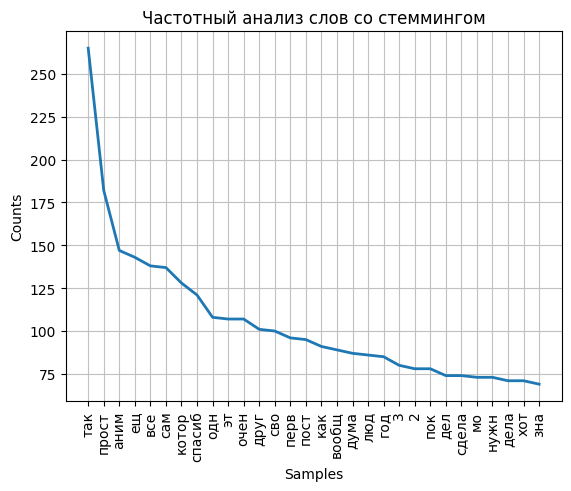

<Axes: title={'center': 'Частотный анализ слов со стеммингом'}, xlabel='Samples', ylabel='Counts'>

In [23]:
# Стемминг
from nltk.stem.snowball import SnowballStemmer


snow_stemmer = SnowballStemmer(language='russian')
text_stemmed = map(lambda word: snow_stemmer.stem(word), text_f)
f_dist = FreqDist(text_stemmed)
print('\n'.join(map(str, f_dist.most_common(10))))
f_dist.plot(30, cumulative=False, title='Частотный анализ слов со стеммингом')

### Применение готовой модели для анализа датасета

In [24]:
import pickle
from tensorflow.keras.preprocessing.sequence import pad_sequences
from keras.models import load_model
import numpy as np

In [25]:
# взял модель с https://www.kaggle.com/code/egormanovel/toxic-comment-lstm/notebook, прогнал в гугл колабе, сериализовал модель и токенайзер для использования с нашим датасетом
# https://colab.research.google.com/drive/127pwYXMbmEg4xbcP23btVa6xp9yXAsyn?usp=sharing

model = load_model('data/model.keras')
with open('data/tokenizer.pickle', 'rb') as handle:
    tokenizer = pickle.load(handle)

In [26]:
X = tokenizer.texts_to_sequences(df['comment'].tolist())
max_comment_length = 300
X_pad = pad_sequences(X, maxlen=max_comment_length)

predictions = model.predict(X_pad,verbose=1)
toxic_comments = df[(np.round(predictions) == 1.0)]['comment'].tolist()
for comment in toxic_comments[0:20]:
    print(comment)

160/160 ━━━━━━━━━━━━━━━━━━━━ 8s 46ms/step
дурачок
ха ха я тут живу
где вы там бизнесменов видели одни пидарасы и жулики
а если кто то сам себе бармен кодироваться
а если его в поле закопать гандоны прорастут или сразу хуи будут по осени
ну а кому же ещё если вы знаете лично хоть одного росгвардейца и он вам кажется ок то знайте вы мудак нормальные люди им плюют в лицо при встрече а не жмут руку
просто цирк какой же стыд
а чей то у рамзанчика на лбу след от поцелуя боженьки
сайт эха заблочен но вроде венедиктов говорил что они остались и будут продолжать в соцсетях так что желательно давать альтернативные ссылки на их публикации
раша врет и пытается навредить ес в том числе используя тему короновируса и канал раша тудей европейская комиссия уже идентифицировала как минимум 150 скоординированных компаний по дезинформации из россии об этом и свежайший репортажик 1 го немецкого канала ard
і це чудово
россия не хотела в одну харю снижать добычу сейчас добычу снижают все члены опек есть разн

In [27]:
df['target'] = np.round(predictions)
df['target'].value_counts()

,count
target,
0.0,3423
1.0,1674


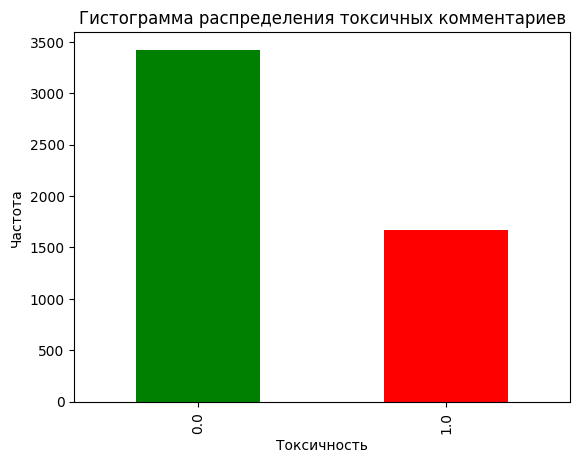

In [28]:
df['target'].value_counts().plot(kind='bar', color=['green', 'red'])
plt.xlabel('Токсичность')
plt.ylabel('Частота')
plt.title('Гистограмма распределения токсичных комментариев')
plt.show()

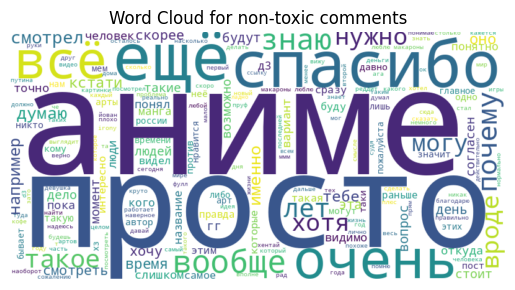

In [29]:
non_toxic_text = reduce(lambda x, y: x + y, df[df['target'] == 0.0]['tokenized'].values)
wordcloud_toxic = WordCloud(width=800, height=400, background_color='white').generate(' '.join(non_toxic_text))
plt.imshow(wordcloud_toxic, interpolation='bilinear')
plt.axis('off')
plt.title('Word Cloud for non-toxic comments')
plt.show()

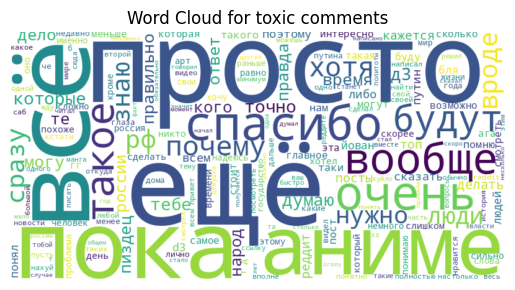

In [30]:
toxic_text = reduce(lambda x, y: x + y, df[df['target'] == 1.0]['tokenized'].values)
wordcloud_toxic = WordCloud(width=800, height=400, background_color='white').generate(' '.join(toxic_text))
plt.imshow(wordcloud_toxic, interpolation='bilinear')
plt.axis('off')
plt.title('Word Cloud for toxic comments')
plt.show()